#### Requirements

In [1]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester, backtester_v2
from src.strategies import run_momentum_strategy
from src.summary import summary

In [2]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

returns_array = np.array(returns)
prices_array = np.array(prices)

possible_trade_days = np.arange(lookback + 1, len(prices_array) - 1)

In [3]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

#### Trade-Count Matched Strategy

In [4]:
def generate_random_signal_v3(prices, lookback):

    possible_trade_days = np.arange(lookback + 1, len(prices) - 1)

    trade_days = np.random.choice(possible_trade_days, size = 89, replace = False)
    trade_days = np.sort(trade_days)

    random_signal = [np.nan] * lookback

    state = 0

    for i in range(lookback, len(prices)):
        if i in trade_days:
            state = 1 - state

        random_signal.append(state) 

    return random_signal

In [5]:
def generate_random_signal_v3_optimised(prices_array, possible_trade_days, lookback):

    trade_days = np.random.choice(possible_trade_days, size = 89, replace = False)

    switch_array = np.zeros_like(prices_array)

    switch_array[trade_days] = 1

    cumulative_switches = np.cumsum(switch_array)

    random_signal_array = np.mod(cumulative_switches, 2)
    random_signal_array[:lookback] = np.nan

    return random_signal_array

In [6]:
random_signal = generate_random_signal_v3(prices, lookback)

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return          1.579712
cagr                  0.037660
annual_volatility     0.111457
annual_sharpe         0.387400
max_drawdown         -0.425578
calmar                0.088492
time_invested         0.439938
trades               89.000000
dtype: float64

In [7]:
def run_simulation_v3(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v3(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [8]:
def run_simulation_v3_optimised(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v3_optimised(prices_array, possible_trade_days, lookback)
        random_result = backtester_v2(returns_array, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result

In [9]:
np.random.seed(44)

simulation_output = run_simulation_v3_optimised(100000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.094666,0.045053,0.108100,0.462097,-0.291098,0.154771,0.416254,89
1,6.207126,0.080092,0.114809,0.728532,-0.221963,0.360834,0.510217,89
2,1.315091,0.033288,0.132055,0.313943,-0.438860,0.075852,0.418731,89
3,1.096232,0.029293,0.117943,0.303794,-0.306537,0.095562,0.481424,89
4,1.217444,0.031553,0.134885,0.297689,-0.479669,0.065780,0.487461,89
...,...,...,...,...,...,...,...,...
99995,2.132962,0.045555,0.140502,0.387247,-0.461270,0.098760,0.557121,89
99996,3.171788,0.057300,0.126603,0.503530,-0.322661,0.177586,0.507430,89
99997,2.071602,0.044749,0.134761,0.392089,-0.571814,0.078257,0.463622,89
99998,2.171861,0.046058,0.131797,0.407678,-0.335776,0.137170,0.541641,89


Mean Sharpe: 0.37579
Median Sharpe: 0.37052
Max Sharpe: 1.0105
P Value: 0.03649
Avg Trades: 89
Avg Time Invested: 0.5
Number Of Simulations: 100000


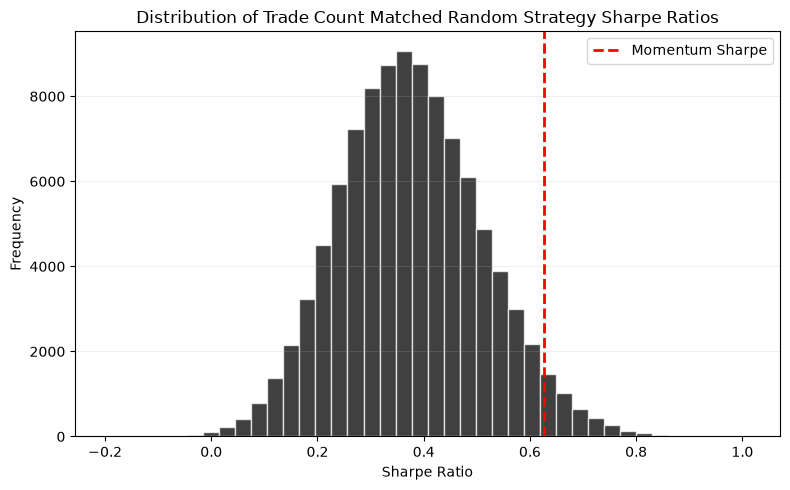

In [10]:
trade_count_summary = summary(simulation_df, momentum_results, "trade_count_matched_random_strategy")